# Motivation 3: ageing shrinks the feasible speed x DVFS configuration space

**Message.** Every (speed, CPU level) configuration has a throughput (QoS) and an energy per metre.
Ageing hardly moves the configurations (energy per metre changes by < 2 %), but it lowers the energy
per metre the same BMS reading can pay for. The feasible region (QoS met and energy below the SOH
line) therefore shrinks from the top, and the fastest feasible configuration needs a different
speed *and* a different CPU level at every SOH. How the region is cut depends on the workload:
at low complexity the battery is the binding limit, at high complexity the QoS (compute) limit
caps the speed and leaves less room to trade. Speed and DVFS have to be co-adapted to both the
long-term battery state and the workload.

**Setting.** Low (C = 1), medium (C = 2) and high (C = 3) complexity, the benchmark workload levels;
10 km mission; the same initial SOC 0.33 in all panels; SOH 1.0 / 0.9 / 0.8 from the same
BMS reading, so the dashed budget lines are identical in all panels.

**Data.** Each point is a complete simulated mission in `RobotEnv` (test mode, +-20 % workload
jitter) at a constant speed and CPU DVFS level (11 levels, 0.50-2.04 GHz). x: throughput at the
nominal workload C (no jitter margin), against the QoS target of 25 batch/s. y: cell-side energy per metre (the curves are drawn from the SOH 0.8
runs; SOH 1.0 / 0.9 differ by < 2 %). Dashed lines: energy per metre available above the 5 % SOC
reserve. A configuration is feasible at an SOH if it meets QoS and the mission at that SOH completes
with true SOC >= reserve.

In [241]:
import sys
from pathlib import Path

REPO = Path.cwd().resolve()
while not (REPO / 'envs').is_dir() and REPO != REPO.parent:   # notebook lives in <repo>/figures
    REPO = REPO.parent
sys.path.insert(0, str(REPO))

import json
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import envs  # noqa: F401  (sys.path for battery_model)
from envs.robot_env import (RobotEnv, ECMParams, StressParams, _voc, compute_throughput,
                            tight_soc_init, CPU_FREQ_GHZ)
from envs.test_env import EVAL_CONFIG, make_robot

OUT = REPO / 'figures' / 'pdf'
OUT.mkdir(parents=True, exist_ok=True)
DATA = REPO / 'figures' / 'data'          # cached simulation results (plots re-run without simulating)
DATA.mkdir(parents=True, exist_ok=True)
RECOMPUTE = False                         # True: ignore the cache (e.g. after changing the env/ECM code)


def cached(name, settings, compute):
    """Return compute(), cached in DATA/<name>.pkl. The cache is reused only if it was made
    with the same settings; changing any setting recomputes it automatically."""
    path = DATA / f'{name}.pkl'
    key = json.dumps(settings, sort_keys=True, default=str)
    if path.exists() and not RECOMPUTE:
        with open(path, 'rb') as fh:
            blob = pickle.load(fh)
        if blob['settings'] == key:
            print(f'loaded {path.relative_to(REPO)}')
            return blob['data']
        print(f'{path.name}: settings changed, recomputing')
    data = compute()
    with open(path, 'wb') as fh:
        pickle.dump({'settings': key, 'data': data}, fh)
    print(f'saved {path.relative_to(REPO)}')
    return data

plt.rcParams.update({
    'font.family': 'serif', 'font.serif': ['Times New Roman', 'STIXGeneral', 'DejaVu Serif'],
    'mathtext.fontset': 'stix', 'font.size': 16, 'axes.titlesize': 16, 'axes.labelsize': 16,
    'xtick.labelsize': 16, 'ytick.labelsize': 16, 'legend.fontsize': 16,
    'axes.grid': True, 'grid.linestyle': '--', 'grid.linewidth': 0.4, 'grid.color': '#c8c8c8',
    'pdf.fonttype': 42, 'savefig.bbox': 'tight', 'savefig.pad_inches': 0.02,
})

## Settings

In [242]:
CS = {'low': 1.0, 'medium': 2.0, 'high': 3.0}           # workload complexity per panel
L = 10_000.0                                             # mission length [m]
SOHS = [1.00, 0.90, 0.80]
SPEEDS = [2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0]               # 0.5 m/s steps (<= 1.5 m/s is far above every budget)
LEVELS = list(range(len(CPU_FREQ_GHZ)))                  # DVFS level indices
SEED = 0
QOS_MARGIN = EVAL_CONFIG['baseline_qos_margin']          # 1.05
JITTER = EVAL_CONFIG['test_complexity_jitter']           # 0.2
ROBOT = make_robot(EVAL_CONFIG)
QOS_MIN = max(ROBOT.qos_ref)                             # 25 batch/s at the nominal workload
RESERVE = ROBOT.soc_reserve
SOC0 = 0.33                                              # initial SOC (same BMS reading for every SOH)
print(f'SOC0 = {SOC0:.3f}, QoS threshold = {QOS_MIN:.2f} batch/s, reserve = {RESERVE}')

SOC0 = 0.330, QoS threshold = 25.00 batch/s, reserve = 0.05


## Constant-configuration missions (cached)

In [243]:
def mission(v, k, soh, c, seed=SEED):
    """Full mission at constant speed v and DVFS level k, nominal complexity c."""
    rp = make_robot(dict(EVAL_CONFIG, mission_distance_m=L))
    rp.max_steps = 10**6
    env = RobotEnv(robot=rp, ecm=ECMParams.default(rp), stress=StressParams(), soc_init=SOC0,
                   soh_init=soh, complexity=c, mode='test', complexity_jitter=JITTER)
    env.reset(seed=seed)
    done = False
    while not done:
        _, _, term, trunc, _ = env.step([v, k])
        done = term or trunc
    return dict(epd=env.total_energy_j / max(env.distance_m, 1e-9),
                completed=env.distance_m >= L - 1e-6, soc_end=env.battery.soc)


def budget_per_m(soh):
    """Cell-side energy above the reserve per mission metre [J/m]."""
    s = np.linspace(RESERVE, SOC0, 400)
    return np.trapezoid([_voc(x, soh) for x in s], s) * ROBOT.Q_n * soh / L


def run_missions():
    rows = []
    for c in CS.values():
        for soh in SOHS:
            for v in SPEEDS:
                for k in LEVELS:
                    rows.append(dict(c=c, soh=soh, speed=v, level=k, freq=float(CPU_FREQ_GHZ[k]),
                                     **mission(v, k, soh, c)))
    return pd.DataFrame(rows)


data = cached('motivation_3_missions',
              dict(cs=list(CS.values()), L=L, sohs=SOHS, speeds=SPEEDS, levels=CPU_FREQ_GHZ.tolist(),
                   seed=SEED, soc0=SOC0, cfg=EVAL_CONFIG), run_missions)
data['thr'] = compute_throughput(data.speed, data.freq, data.c)   # nominal workload (no jitter margin)
data['qos_ok'] = data.thr >= QOS_MIN - 1e-9
data['feasible'] = data.qos_ok & data.completed & (data.soc_end >= RESERVE)
BUDGET = {h: budget_per_m(h) for h in SOHS}
print(len(data), 'missions | budget J/m:', {h: round(b, 2) for h, b in BUDGET.items()})

loaded figures/data/motivation_3_missions.pkl
693 missions | budget J/m: {1.0: np.float64(7.16), 0.9: np.float64(6.37), 0.8: np.float64(5.63)}


## Fastest feasible configuration per SOH

In [244]:
best = {}                                                 # (c, soh) -> fastest feasible configuration
for c in CS.values():
    for soh in SOHS:
        f = data[(data.c == c) & (data.soh == soh) & data.feasible]
        if f.empty:
            continue
        f = f[f.speed == f.speed.max()]                  # fastest speed, then the cheapest level
        best[c, soh] = f.loc[f.epd.idxmin()]
pd.DataFrame([dict(c=c, soh=h, speed=b.speed, freq_ghz=b.freq, thr=b.thr, epd=b.epd, soc_end=b.soc_end,
                   n_feasible=int(data[(data.c == c) & (data.soh == h) & data.feasible].shape[0]))
              for (c, h), b in best.items()]).round(3)

,c,soh,speed,freq_ghz,thr,epd,soc_end,n_feasible
0,1.0,1.0,5.0,0.806,25.364,6.534,0.076,72
1,1.0,0.9,4.5,0.653,25.019,6.086,0.063,58
2,1.0,0.8,4.0,0.653,25.243,5.623,0.050,19
3,2.0,1.0,5.0,1.267,25.349,6.974,0.058,54
4,2.0,0.9,4.0,1.114,25.450,5.983,0.068,33
5,2.0,0.8,3.0,0.960,25.563,5.553,0.054,3
6,3.0,1.0,5.0,1.882,25.683,7.079,0.053,34
7,3.0,0.9,4.0,1.421,25.114,6.200,0.058,13


## Figure

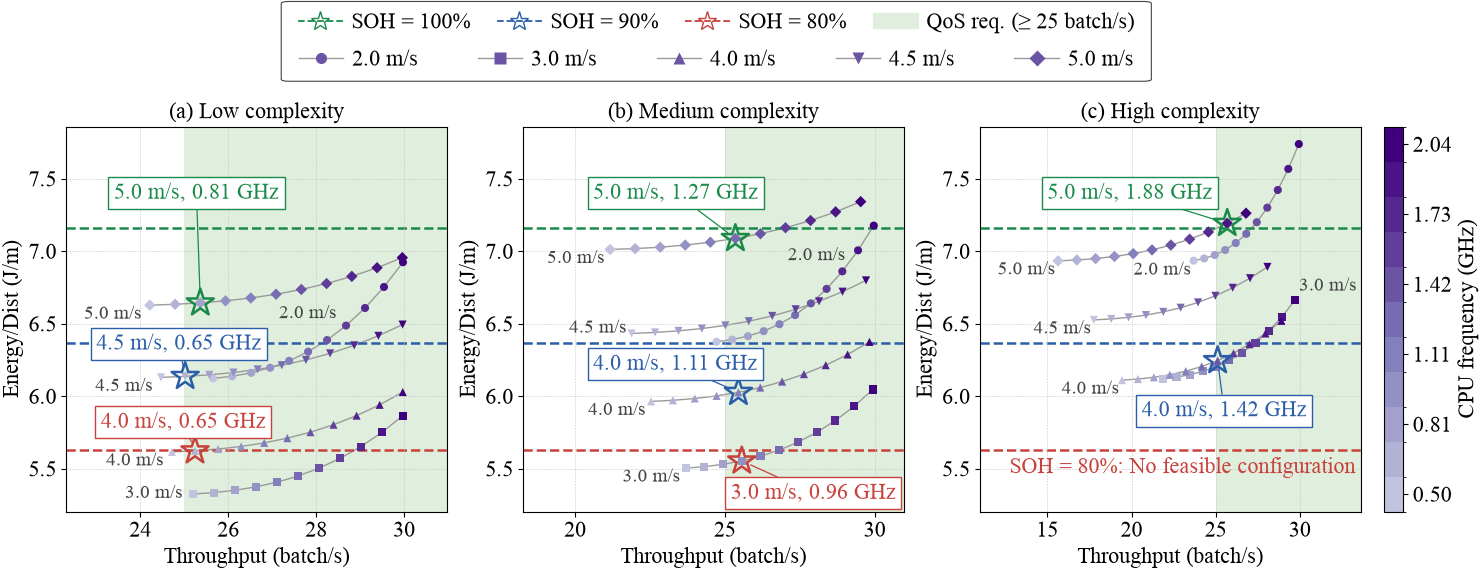

In [245]:
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

STYLE = {1.00: dict(color='#1a8a4a', marker='*', label='SOH = 100%'),   # SOH: colour only
         0.90: dict(color='#2a5ea8', marker='*', label='SOH = 90%'),
         0.80: dict(color='#c8413b', marker='*', label='SOH = 80%')}
SPEED_MARKER = {2.0: 'o', 2.5: 'p', 3.0: 's', 3.5: 'h', 4.0: '^', 4.5: 'v', 5.0: 'D'}   # speed: marker shape
# Discrete purple ramp, one shade per DVFS level (light = low, dark = high frequency); starts at 0.35
# so the lowest level stays visible without marker edges, hue distinct from the SOH colours
CMAP = ListedColormap(plt.get_cmap('Purples')(np.linspace(0.35, 1.0, len(CPU_FREQ_GHZ))))
edges = np.r_[CPU_FREQ_GHZ[0] - 0.077, 0.5 * (CPU_FREQ_GHZ[1:] + CPU_FREQ_GHZ[:-1]), CPU_FREQ_GHZ[-1] + 0.077]
FNORM = BoundaryNorm(edges, CMAP.N)
FS = 16                                                   # annotation font size
SPEED_FS = 14                                             # speed labels
LABEL_GAP = 0.13                                          # min. vertical gap of speed labels [J/m]
QOS_COLOR = '#dfeedd'                                     # QoS-met region
SPEEDS_BASE = [2.0, 3.0, 5.0]                             # always drawn; plus every best speed
SPEED_LABEL_RIGHT = {(2.0, 2.0), (3.0, 2.0)}                         # (C, speed): label below-right (avoids a curve)
# hand-placed labels (data coordinates) where the default position collides with other curves
SPEED_LABEL_AT = {(3.0, 3.0): (29.95, 6.76, 'left', 'center'),   # right of the curve end (overlaps 4.0 m/s)
                  (1.0, 3.0): (24.9, 5.30, 'right', 'center'),
                  (1.0, 3.5): (24.9, 5.46, 'right', 'center'),
                  (1.0, 2.0): (28.45, 6.57, 'right', 'center'),    # (C, speed): x, y, ha, va
                  (2.0, 2.0): (29.0, 6.97, 'right', 'center'),
                  (2.0, 4.5): (21.7, 6.47, 'right', 'center'),
                  (3.0, 2.0): (23.5, 6.87, 'right', 'center')}
# speed labels with a leader line to the curve end: (C, speed): text x, y (none used)
SPEED_LABEL_ARROW = {}
BEST_LABEL_AT = {(1.0, 1.00): (23.4, 7.40), (1.0, 0.90): (23.0, 6.36), (1.0, 0.80): (23.1, 5.82),
                 (2.0, 1.00): (20.6, 7.40), (2.0, 0.90): (20.6, 6.22), (2.0, 0.80): (25.2, 5.33),
                 (3.0, 1.00): (15.0, 7.40), (3.0, 0.90): (22.4, 5.78)}   # (C, SOH): x, y of the box
X_HI = {3.0: 33.6}                                         # per-panel x upper limit: room for the 3.0 m/s label in (c)
TITLE = {'low': '(a) Low complexity', 'medium': '(b) Medium complexity',
         'high': '(c) High complexity'}

plot = data[data.soh == 0.80]                             # configurations (SOH 0.8 runs)
# same speed curves in every panel: the base speeds plus the best speeds of all panels
speeds_plot = sorted(set(SPEEDS_BASE) | {b.speed for b in best.values()})
y_lo, y_hi = plot.epd.min() - 0.3, BUDGET[1.0] + 0.5
fig, axes = plt.subplots(1, 3, figsize=(20.0, 5), sharey=True)
for ax, (name, c) in zip(axes, CS.items()):
    curve = plot[(plot.c == c) & plot.speed.isin(speeds_plot)]
    vis = curve[curve.epd <= y_hi]                         # per-panel x range (automatic ticks)
    b_thr = [best[c, h].thr for h in SOHS if (c, h) in best]
    x_lo = vis.thr.min() - 0.33 * (vis.thr.max() - vis.thr.min())   # room for the speed labels
    b_max = max(b_thr, default=x_lo)
    x_hi = X_HI.get(c, max(vis.thr.max() + 1.0, QOS_MIN + 1.0, b_max + 0.45 * (b_max - x_lo)))
    ax.axvspan(QOS_MIN, x_hi, color=QOS_COLOR, zorder=0, lw=0)
    for v in speeds_plot:
        g = curve[curve.speed == v].sort_values('level')
        ax.plot(g.thr, g.epd, color='#9a9a9a', lw=1.0, zorder=1)
        sc = ax.scatter(g.thr, g.epd, c=g.freq, cmap=CMAP, norm=FNORM, s=34, edgecolors='none',
                        marker=SPEED_MARKER[v], zorder=2)
    # speed labels below-left of the left end of each curve, pushed apart where curves start close together
    ends = sorted(((curve[curve.speed == v].sort_values('level').iloc[0], v) for v in speeds_plot),
                  key=lambda r: r[0].epd)
    y_prev = -np.inf
    for r, v in ends:
        right = (c, v) in SPEED_LABEL_RIGHT              # right-side labels do not collide with the rest
        free = right or (c, v) in SPEED_LABEL_AT or (c, v) in SPEED_LABEL_ARROW   # placed elsewhere
        y_txt = r.epd if free else max(r.epd, y_prev + LABEL_GAP)
        y_prev = y_prev if free else y_txt
        if (c, v) in SPEED_LABEL_ARROW:                  # leader line to the high-frequency end
            g = curve[curve.speed == v].sort_values('level').iloc[-1]
            ax.annotate(f'{v:.1f} m/s', (g.thr, g.epd), xytext=SPEED_LABEL_ARROW[c, v], fontsize=SPEED_FS,
                        ha='left', va='center', color='#444444',
                        arrowprops=dict(arrowstyle='-', color='#777777', lw=0.9, shrinkA=2, shrinkB=4))
        elif (c, v) in SPEED_LABEL_AT:
            x_t, y_t, ha, va = SPEED_LABEL_AT[c, v]
            ax.text(x_t, y_t, f'{v:.1f} m/s', fontsize=SPEED_FS, ha=ha, va=va, color='#444444')
        elif y_txt <= y_hi:
            ax.text(r.thr + (0.2 if right else -0.2), y_txt, f'{v:.1f} m/s', fontsize=SPEED_FS, va='top',
                    ha='left' if right else 'right', color='#444444')
    groups = {}                                           # SOH levels sharing a best configuration
    for soh in SOHS:
        ax.axhline(BUDGET[soh], color=STYLE[soh]['color'], ls='--', lw=1.8, zorder=1)
        if (c, soh) in best:
            groups.setdefault((best[c, soh].speed, best[c, soh].level), []).append(soh)
        else:                                             # no configuration meets QoS within the budget
            ax.text(x_hi - 0.3, BUDGET[soh] - 0.05, f"{STYLE[soh]['label']}: No feasible configuration",
                    fontsize=FS, color=STYLE[soh]['color'], va='top', ha='right')
    for (v, k), hs in groups.items():
        b = best[c, hs[0]]
        y = float(curve[(curve.speed == v) & (curve.level == k)].epd.iloc[0])
        for i, soh in enumerate(hs):                      # concentric markers if several SOH share it
            ax.scatter([b.thr], [y], s=420 + 250 * i, facecolors='none', edgecolors=STYLE[soh]['color'],
                       linewidths=1.8, marker=STYLE[soh]['marker'], zorder=4 + i)
        col = STYLE[hs[0]]['color'] if len(hs) == 1 else '#222222'
        box = dict(fontsize=FS, color=col, zorder=6, bbox=dict(boxstyle='square,pad=0.25', fc='white', ec=col, lw=1.0))
        if (c, hs[0]) in BEST_LABEL_AT:                  # box in free space, thin leader line to the point
            ax.annotate(f'{v:.1f} m/s, {b.freq:.2f} GHz', (b.thr, y), xytext=BEST_LABEL_AT[c, hs[0]],
                        textcoords='data', ha='left', va='center',
                        arrowprops=dict(arrowstyle='-', color=col, lw=0.9, shrinkA=0, shrinkB=7), **box)
        else:
            ax.annotate(f'{v:.1f} m/s, {b.freq:.2f} GHz', (b.thr, y), xytext=(16, -4),
                        textcoords='offset points', ha='left', va='top', **box)
    ax.set_xlim(x_lo, x_hi)
    # ax.set_ylim(y_lo, y_hi)
    ax.set_title(TITLE[name].format(c=c))
    ax.set_xlabel('Throughput (batch/s)')
    ax.set_ylabel('Energy/Dist (J/m)')
    ax.tick_params(labelleft=True)                        # y tick labels on every panel (sharey hides them)
cb = fig.colorbar(sc, ax=axes, pad=0.015, ticks=CPU_FREQ_GHZ[::2])
cb.ax.set_yticklabels([f'{f:.2f}' for f in CPU_FREQ_GHZ[::2]])
cb.set_label('CPU frequency (GHz)')
h = [plt.Line2D([], [], color=STYLE[s]['color'], ls='--', lw=1.3, marker='*', mfc='none', ms=14)
     for s in SOHS]
# one legend box, two independently centred rows (SOH + QoS region; speeds): two frameless
# legends inside one common frame, so the speed row is not stretched by the long QoS entry
from matplotlib.patches import FancyBboxPatch
from matplotlib.transforms import Bbox
h1 = h + [Patch(color=QOS_COLOR)]
l1 = [STYLE[s]['label'] for s in SOHS] + [f'QoS req. (\u2265 {QOS_MIN:g} batch/s)']
h2 = [plt.Line2D([], [], ls='-', lw=1.0, color='#9a9a9a', marker=SPEED_MARKER[v], mfc=CMAP(0.6),
                 mec='none', ms=8) for v in speeds_plot]
l2 = [f'{v:.1f} m/s' for v in speeds_plot]
LEG_X, LEG_Y = 0.45, 1.135                                # top centre of the legend box (figure coords)
leg1 = fig.legend(h1, l1, ncol=len(h1), loc='upper center', bbox_to_anchor=(LEG_X, LEG_Y), frameon=False,
                  columnspacing=1.2, handletextpad=0.4, borderaxespad=0.2)
fig.canvas.draw()
rend = fig.canvas.get_renderer()
y2 = fig.transFigure.inverted().transform(leg1.get_window_extent(rend))[0, 1]
leg2 = fig.legend(h2, l2, ncol=len(h2), loc='upper center', bbox_to_anchor=(LEG_X, y2 + 0.012), frameon=False,
                  columnspacing=2.68, handletextpad=0.4, borderaxespad=0.2)
fig.canvas.draw()
bb = Bbox.union([leg1.get_window_extent(rend), leg2.get_window_extent(rend)]).transformed(fig.transFigure.inverted())
fig.patches.append(FancyBboxPatch((bb.x0, bb.y0), bb.width, bb.height, boxstyle='round,pad=0.004',
                                  transform=fig.transFigure, fc='white', ec='#444444', lw=0.8, zorder=1))
fig.savefig(OUT / 'motivation_3.pdf')
plt.show()

Dashed lines: energy per metre available above the reserve at each SOH (same in all panels).
Points: one (speed, CPU level) configuration each, darker = higher frequency; drawn in every panel: 2, 3 and 5 m/s plus
the speeds of all best configurations (0.5 m/s grid). Hollow markers: fastest feasible configuration (QoS met, ends above the
reserve) at each SOH.